# Estimating ϑ (vartheta) for Women's Footwear

Bach et al. (2025) follow He and Hollenbeck (2020) and use the relationship:

```
true_elasticity ≈ θ_raw × (1 / ϑ)
```

where ϑ is the shape parameter of the Pareto distribution that describes how
sales quantities are distributed across products in a category.

He and Hollenbeck estimated ϑ ≈ 0.5 for **toys**, giving a rescale factor of
2. Footwear may have a different ϑ. This notebook estimates it three ways.

**Methods:**

| Method | Idea |
|---|---|
| Approach A | Fit power law to sorted SALES_RANK directly. Slope = 1/ϑ. |
| Approach B | Regress log(REVIEW_COUNT) on log(SALES_RANK). Slope = -ϑ. |
| Approach C | Compare against published ϑ values from the literature. |

The summary table at the end applies each ϑ̂ to your DoubleML headline results.

**v7.1 fix:** column auto-pick prefers `SALES_RANK_original` (raw integer rank). The previous version picked `SALES_RANK`, which in this pipeline is `log(1/rank)` and so produces zero positive values, breaking Approach A.\n\n**v8.1 fix:** `find_shoes_parquet()` now verifies each candidate is a readable file before returning it. Previously, glob could return ghost paths from a stale Drive cache, which then crashed `os.path.getsize` in the next cell.\n

## Setup

In [ ]:
# ── Shared (cross-bucket) output config ─────────────────────────────────
# ϑ is a category-level structural parameter; identical for all buckets.
from pathlib import Path

def _find_project_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'data_preparation').exists() and (p / 'code').exists():
            return p
    raise RuntimeError('Cannot find project root')

PROJECT_ROOT = _find_project_root()
OUTPUT_DIR   = PROJECT_ROOT / 'data' / '_shared' / 'vartheta'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'OUTPUT_DIR : {OUTPUT_DIR}')

## Configuration

In [ ]:
# ── CONSTANTS ──────────────────────────────────────────────────────────────
# Update these once if your DoubleML elasticity numbers change. They are used
# in the final summary table to apply rescaling.

PLR_HEADLINE = -0.103     # raw θ from PLR baseline (no IV)
PLIV_HEADLINE = -0.975    # raw θ from PLIV Controls-only spec (the headline)
MIN_OBS = 50              # minimum number of observations needed for a valid fit
SUMMARY_CSV = str(OUTPUT_DIR / "vartheta_estimates_shoes.csv")
BACH_VARTHETA = 0.5       # toys reference value from He & Hollenbeck (2020)


## Helper functions

In [ ]:
import os
import glob
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt


def find_shoes_parquet():
    """Search common Drive paths for the shoes parquet file.

    v8.1 fix: glob in Colab can return paths that look real but fail
    when the OS actually tries to stat them (stale Drive cache, lazy
    listings, ghost shortcuts). We now verify each candidate is a
    readable file before returning it.
    """
    # Local search: project data folder (PROJECT_ROOT defined in bucket-output-config cell)

    search_roots = [

        str(PROJECT_ROOT / "data"),

        str(PROJECT_ROOT),

    ]
    patterns = [
        "**/amazon_shoes*combined*.parquet",
        "**/amazon_shoes*.parquet",
        "**/shoes*combined*.parquet",
    ]
    candidates = []
    for root in search_roots:
        if not os.path.exists(root):
            continue
        for pat in patterns:
            try:
                candidates.extend(glob.glob(os.path.join(root, pat), recursive=True))
            except Exception:
                pass
    # de-dupe AND verify each path is a real, readable file
    seen, unique = set(), []
    for c in candidates:
        if c in seen:
            continue
        seen.add(c)
        try:
            if os.path.isfile(c) and os.access(c, os.R_OK):
                # Touch the file with getsize to flush any stale Drive cache
                os.path.getsize(c)
                unique.append(c)
        except OSError:
            # Path exists in glob's listing but is not openable. Skip it.
            continue
    return unique


def find_first_match(df_columns, candidates):
    """Return first column name from candidates that exists in df_columns."""
    return next((c for c in candidates if c in df_columns), None)


def loglog_ols(y_log, x_log, label_y="y", label_x="x"):
    """Fit a log-log OLS and return fit object plus summary dict.

    This is the workhorse used by both Approach A and Approach B since both
    are log-log power-law fits with different variables.
    """
    if len(y_log) < MIN_OBS:
        raise RuntimeError(
            f"Only {len(y_log)} observations — need at least {MIN_OBS}."
        )
    X = sm.add_constant(x_log)
    fit = sm.OLS(y_log, X).fit()
    return {
        "fit": fit,
        "intercept": fit.params[0],
        "slope": fit.params[1],
        "r_squared": fit.rsquared,
        "n_obs": len(y_log),
        "label_y": label_y,
        "label_x": label_x,
    }


def print_loglog_result(result, approach_label, vartheta_value, vartheta_formula):
    """Print a standardized result block for a log-log fit."""
    print("=" * 60)
    print(approach_label)
    print("=" * 60)
    print(f"Number of observations: {result['n_obs']:,}")
    print(result["fit"].summary().tables[1])
    print()
    print(f"Slope ({result['label_y']} on {result['label_x']}): {result['slope']:.4f}")
    if not np.isnan(vartheta_value):
        print(f"Implied ϑ̂ = {vartheta_formula}: {vartheta_value:.4f}")
        print(f"Rescale factor 1/ϑ̂: {1.0/vartheta_value:.3f}")
    else:
        print("ϑ̂ undefined (slope sign or magnitude invalid).")
    print(f"R²: {result['r_squared']:.4f}")


def plot_loglog_fit(result, vartheta_value, x_label, y_label, title):
    """Standardized scatter + fit line plot for a log-log result."""
    x_log = np.asarray(result["fit"].model.exog[:, 1])  # the log_x column
    y_log = np.asarray(result["fit"].model.endog)
    x_sorted = np.sort(x_log)

    plt.figure(figsize=(8, 5))
    plt.scatter(x_log, y_log, alpha=0.3, s=8, label="Observed")
    plt.plot(
        x_sorted,
        result["intercept"] + result["slope"] * x_sorted,
        color="red", linewidth=2,
        label=f"Fit: slope={result['slope']:.3f}, ϑ̂={vartheta_value:.3f}",
    )
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()



## Load data and identify columns

In [ ]:
# Auto-find the parquet file
found = find_shoes_parquet()
if found:
    print("Found candidate parquet file(s):")
    for i, p in enumerate(found):
        try:
            size_mb = os.path.getsize(p) / 1e6
            print(f"  [{i}] {p}  ({size_mb:.1f} MB)")
        except OSError as e:
            print(f"  [{i}] {p}  (could not read size: {e})")
    PARQUET_PATH = found[0]
    print(f"\nUsing the first match: {PARQUET_PATH}")
    print("To use a different file, set PARQUET_PATH manually below.")
else:
    print("No parquet match found via auto-search.")
    print("Expected at:", PROJECT_ROOT / "data" / "amazon_shoes_8_combined.parquet")

    print("Set PARQUET_PATH manually below if your file is elsewhere.")
    PARQUET_PATH = None

# ── OVERRIDE: uncomment and set explicitly if auto-find picks wrong one ───
# PARQUET_PATH = str(PROJECT_ROOT / "data" / "amazon_shoes_8_combined.parquet")


In [ ]:
# Load the parquet
if PARQUET_PATH is None:
    raise RuntimeError("PARQUET_PATH not set. See the cell above for guidance.")
if not os.path.exists(PARQUET_PATH):
    raise FileNotFoundError(f"PARQUET_PATH does not exist: {PARQUET_PATH}")

df = pd.read_parquet(PARQUET_PATH)
print(f"Loaded: {PARQUET_PATH}")
print(f"Shape: {df.shape}")
df.head(3)


In [30]:
# Identify columns (names vary across pipeline versions)
# IMPORTANT: SALES_RANK in the prepared pipeline data is log(1/sales_rank),
# i.e. already log-transformed and negative. For the Pareto fit we need the
# RAW integer rank, which lives in SALES_RANK_original in the combined parquet.
# We list it first so auto-pick prefers it.
COL_MAP = {
    "rank":   ["SALES_RANK_original", "Sales Rank: Current", "SalesRank",
               "sales_rank_avg", "sales_rank", "SALES_RANK"],  # SALES_RANK is last fallback only
    "review": ["REVIEW_COUNT", "review_count", "Reviews: Review Count", "ReviewCount"],
    "date":   ["date", "DATE", "Date"],
    "asin":   ["ASIN", "asin"],
}

cols = {role: find_first_match(df.columns, candidates) for role, candidates in COL_MAP.items()}

assert cols["rank"] is not None, f"Could not find rank column. Tried: {COL_MAP['rank']}"

# Sanity check: rank column should have positive values (raw integer rank).
# If we accidentally picked a log-transformed column, all values will be negative.
n_positive = (df[cols["rank"]] > 0).sum()
n_total = df[cols["rank"]].notna().sum()
if n_positive == 0 and n_total > 0:
    raise RuntimeError(
        f"Picked column '{cols['rank']}' has zero positive values "
        f"({n_total:,} non-null rows). This looks like a log-transformed column. "
        f"The Pareto fit needs the RAW integer rank. "
        f"Available columns: {list(df.columns)}"
    )
if n_positive < n_total * 0.9:
    print(f"⚠️  Warning: only {n_positive:,} of {n_total:,} non-null values are positive. "
          f"Expected raw integer rank to be uniformly positive.")

for role, col in cols.items():
    print(f"{role:8s}: {col}")


rank    : SALES_RANK_original
review  : REVIEW_COUNT
date    : date
asin    : ASIN


## Build a single-snapshot dataset

In [31]:
# Build a snapshot with diagnostic checks and graceful fallbacks.

def diagnose_rank_column(df, rank_col):
    '''Print summary stats on the rank column to detect data quality issues.'''
    print("=" * 60)
    print("DATA DIAGNOSTICS")
    print("=" * 60)
    print(f"Total rows:        {len(df):,}")
    print(f"  Non-null:        {df[rank_col].notna().sum():,}")
    print(f"  Positive ( > 0): {(df[rank_col] > 0).sum():,}")
    print(f"  Zero:            {(df[rank_col] == 0).sum():,}")
    print(f"  NaN:             {df[rank_col].isna().sum():,}")
    valid = df[df[rank_col] > 0]
    if len(valid) > 0:
        print(f"  Min (positive):  {valid[rank_col].min():,.0f}")
        print(f"  Max:             {valid[rank_col].max():,.0f}")
        print(f"  Median:          {valid[rank_col].median():,.0f}")


def build_snapshot(df, rank_col, date_col=None, asin_col=None):
    '''Return one valid snapshot of the data, trying multiple strategies.'''
    # Strategy A: latest date with enough valid observations
    if date_col is not None:
        for candidate_date in sorted(df[date_col].dropna().unique(), reverse=True):
            mask = (df[date_col] == candidate_date) & (df[rank_col] > 0)
            if mask.sum() >= MIN_OBS:
                return df[mask].copy(), f"latest valid date: {candidate_date}"

    # Strategy B: best-rank row per ASIN
    if asin_col is not None:
        valid = df[df[rank_col] > 0]
        if len(valid) >= MIN_OBS:
            snap = (valid.sort_values(rank_col)
                         .drop_duplicates(subset=[asin_col], keep="first")
                         .copy())
            return snap, f"one row per ASIN ({len(snap):,} ASINs)"

    # Strategy C: all rows with valid rank
    snap = df[df[rank_col] > 0].copy()
    return snap, "all rows with rank > 0"


diagnose_rank_column(df, cols["rank"])
print()
snap, strategy = build_snapshot(df, cols["rank"], cols["date"], cols["asin"])
snap = snap[snap[cols["rank"]].notna() & (snap[cols["rank"]] > 0)].copy()

print("=" * 60)
print(f"SNAPSHOT BUILT — {strategy}")
print("=" * 60)
print(f"Final rows: {len(snap):,}")
if len(snap) < MIN_OBS:
    raise RuntimeError(
        f"Only {len(snap)} valid rows. Cannot estimate ϑ. "
        f"Check the {cols['rank']} column."
    )
print(f"  Range: {snap[cols['rank']].min():,.0f} to {snap[cols['rank']].max():,.0f}")
print(f"  Median: {snap[cols['rank']].median():,.0f}")


DATA DIAGNOSTICS
Total rows:        1,008,930
  Non-null:        991,192
  Positive ( > 0): 991,192
  Zero:            0
  NaN:             17,738
  Min (positive):  13
  Max:             16,698,679
  Median:          35,681

SNAPSHOT BUILT — latest valid date: 2026-03-30
Final rows: 15,518
  Range: 79 to 2,426,530
  Median: 35,522


## Approach A — Pareto fit on sales rank distribution

Sorts the rank values and fits log(rank) on log(rank order). Under a Pareto
distribution with shape ϑ, the slope of this regression equals 1/ϑ.


In [32]:
# Approach A
ranks_sorted = np.sort(snap[cols["rank"]].values.astype(float))
ranks_sorted = ranks_sorted[ranks_sorted > 0]  # safety filter
order = np.arange(1, len(ranks_sorted) + 1)

result_A = loglog_ols(
    y_log=np.log(ranks_sorted),
    x_log=np.log(order),
    label_y="log_rank",
    label_x="log_order",
)
vartheta_A = 1.0 / result_A["slope"] if result_A["slope"] > 0 else float("nan")

print_loglog_result(
    result_A,
    "APPROACH A — Pareto fit on sales rank distribution",
    vartheta_A,
    "1/slope",
)


APPROACH A — Pareto fit on sales rank distribution
Number of observations: 15,518
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.3476      0.015     23.118      0.000       0.318       0.377
x1             1.1429      0.002    661.797      0.000       1.140       1.146

Slope (log_rank on log_order): 1.1429
Implied ϑ̂ = 1/slope: 0.8750
Rescale factor 1/ϑ̂: 1.143
R²: 0.9658


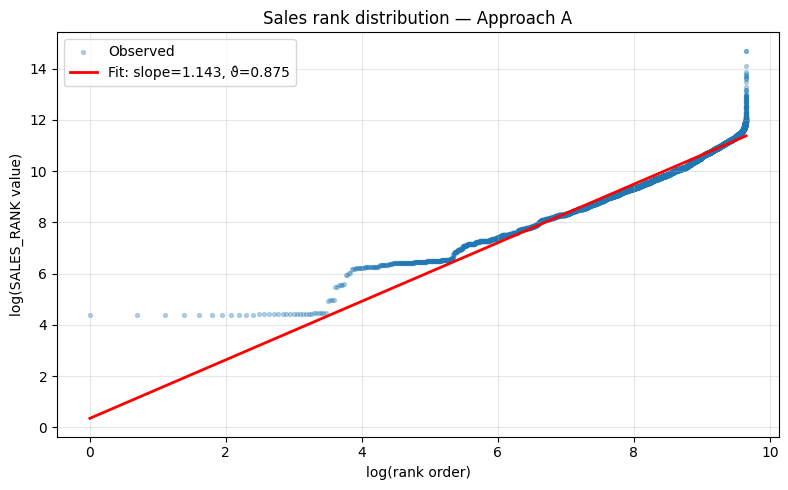

In [33]:
# Visualize Approach A
plot_loglog_fit(
    result_A,
    vartheta_A,
    x_label="log(rank order)",
    y_label="log(SALES_RANK value)",
    title="Sales rank distribution — Approach A",
)


## Approach B — Review counts as quantity proxy

Regresses log(REVIEW_COUNT) on log(SALES_RANK). If reviews are a constant
fraction of sales, the slope recovers -ϑ. Caveat: review rates differ across
brands and price points, so this estimate is noisier than Approach A.


In [34]:
# Approach B
vartheta_B = None
result_B = None

if cols["review"] is None:
    print("No REVIEW_COUNT column found — skipping Approach B.")
else:
    sub = snap[(snap[cols["rank"]] > 0) & (snap[cols["review"]] > 0)].copy()
    print(f"ASINs with review_count > 0: {len(sub):,} of {len(snap):,}")

    if len(sub) < MIN_OBS:
        print(f"Fewer than {MIN_OBS} observations — skipping.")
    else:
        result_B = loglog_ols(
            y_log=np.log(sub[cols["review"]].values),
            x_log=np.log(sub[cols["rank"]].values),
            label_y="log_review_count",
            label_x="log_rank",
        )
        vartheta_B = abs(result_B["slope"])
        print_loglog_result(
            result_B,
            "APPROACH B — log(REVIEW_COUNT) on log(SALES_RANK)",
            vartheta_B,
            "|slope|",
        )


ASINs with review_count > 0: 15,508 of 15,518
APPROACH B — log(REVIEW_COUNT) on log(SALES_RANK)
Number of observations: 15,508
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         13.4863      0.090    150.410      0.000      13.311      13.662
x1            -0.5858      0.009    -67.290      0.000      -0.603      -0.569

Slope (log_review_count on log_rank): -0.5858
Implied ϑ̂ = |slope|: 0.5858
Rescale factor 1/ϑ̂: 1.707
R²: 0.2260


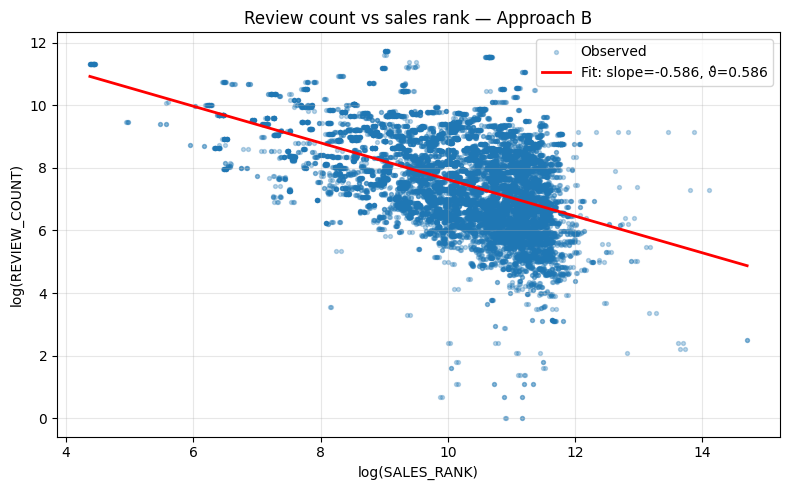

In [35]:
# Visualize Approach B
if result_B is not None:
    plot_loglog_fit(
        result_B,
        vartheta_B,
        x_label="log(SALES_RANK)",
        y_label="log(REVIEW_COUNT)",
        title="Review count vs sales rank — Approach B",
    )


## Approach C — Literature anchors

Published Pareto shape estimates we can use as reference points:

| Category | Source | ϑ̂ |
|---|---|---|
| Toys | He and Hollenbeck (2020); used by Bach et al. (2025) | 0.5 |
| Books | Brynjolfsson, Hu, Smith (2003) | 0.871 |
| Books | Brynjolfsson, Hu, Smith (2010) | 0.613 |
| Books | Chevalier and Goolsbee (2003) | 1.2 |
| Books | Chevalier and Mayzlin (2006) | 0.78 |

Range across categories: roughly 0.5 to 1.2. Footwear-specific estimates are
not in the published literature, so we estimate from the data above.


## Summary table

In [36]:
# Build the summary table by iterating over each ϑ source
HEADLINE_SOURCES = {
    "PLR baseline":        PLR_HEADLINE,
    "PLIV (IV, Controls)": PLIV_HEADLINE,
}


def build_row(source_name, vartheta_value):
    '''Apply rescaling to all headline results for one ϑ value.'''
    row = {"source": source_name, "vartheta": vartheta_value, "rescale": 1/vartheta_value}
    for headline_label, theta in HEADLINE_SOURCES.items():
        row[f"elasticity_{headline_label}"] = theta / vartheta_value
    return row


vartheta_estimates = [
    ("Bach et al. baseline (toys)", BACH_VARTHETA),
]
if not np.isnan(vartheta_A):
    vartheta_estimates.append(("Approach A (rank distribution)", vartheta_A))
if vartheta_B is not None:
    vartheta_estimates.append(("Approach B (review proxy)", vartheta_B))

summary_df = pd.DataFrame([build_row(name, v) for name, v in vartheta_estimates])
summary_df = summary_df.round(3)

print("=" * 100)
print("ϑ ESTIMATES AND IMPLIED ELASTICITIES FOR WOMEN'S FOOTWEAR")
print("=" * 100)
print(summary_df.to_string(index=False))
print()
print("Notes:")
print(f"  - 'rescale' = 1/ϑ̂, the multiplier that converts raw θ to elasticity.")
for label, theta in HEADLINE_SOURCES.items():
    print(f"  - 'elasticity_{label}' applies the rescale to your raw θ = {theta}")

summary_df.to_csv(SUMMARY_CSV, index=False)
print(f"\nSaved: {SUMMARY_CSV}")


ϑ ESTIMATES AND IMPLIED ELASTICITIES FOR WOMEN'S FOOTWEAR
                        source  vartheta  rescale  elasticity_PLR baseline  elasticity_PLIV (IV, Controls)
   Bach et al. baseline (toys)     0.500    2.000                   -0.206                          -1.950
Approach A (rank distribution)     0.875    1.143                   -0.118                          -1.114
     Approach B (review proxy)     0.586    1.707                   -0.176                          -1.664

Notes:
  - 'rescale' = 1/ϑ̂, the multiplier that converts raw θ to elasticity.
  - 'elasticity_PLR baseline' applies the rescale to your raw θ = -0.103
  - 'elasticity_PLIV (IV, Controls)' applies the rescale to your raw θ = -0.975

Saved: vartheta_estimates_shoes.csv


## How to interpret and report

**For your writeup:**

1. Report Approach A's ϑ̂ as your primary shoes-specific estimate.
2. Report Approach B as a robustness check.
3. Cite Bach et al.'s 0.5 (for toys) for reader comparison.
4. Apply the rescale to your headline θ to get the price elasticity of demand.

**Honest caveats:**

- Approach A assumes ranks follow a strict Pareto. Real distributions usually
  deviate in the tails, making the estimate approximate.
- Approach B uses review counts as a quantity proxy. Review rates vary across
  brands and price points, so the estimate is noisier.
- Both inherit the limitations of working with public Amazon data without
  actual sales quantity records.

**Sample sentence for the writeup:**

> "We estimate the Pareto shape parameter ϑ for women's footwear two ways:
> (a) fitting the rank distribution directly (ϑ̂ = X), and (b) regressing log
> review counts on log sales rank (ϑ̂ = Y). Following Bach et al. (2025), we
> apply true_elasticity ≈ θ × (1/ϑ̂) to convert our DoubleML coefficient into
> price elasticity of demand."
